# 07 — Verdieping: het ensemble

Deze notebook hoort bij [`docs/methodologie/ensemble.md`](../docs/methodologie/ensemble.md).
In `-d b` combineert de pipeline het individuele en het cumulatieve spoor met
configureerbare gewichten. We tonen het idee met twee voorspellingen uit het
cumulatieve spoor (SARIMA en ratio), en testen of een combinatie beter is dan elk
afzonderlijk.

> ℹ️ Het volledige `-d b`-ensemble heeft ook individuele aanmelddata nodig en bepaalt
> de gewichten per opleiding via grid search. Hier doen we een vereenvoudigde variant
> met één globaal gewicht.


> 🧭 **Verdieping: een ander spoor.** Het aanbevolen model is het
> [CWF-model](02_cwf_model.ipynb): het is doorgaans nauwkeuriger en
> geeft er een onzekerheidsmarge en betrouwbaarheidslabel bij. Deze notebook legt
> een van de andere sporen uit. Die zijn nog steeds te gebruiken (`-d c`, `-d i`,
> `-d b`), bijvoorbeeld om te vergelijken.


> ℹ️ **Over de demodata.** De notebooks draaien op de meegeleverde, synthetische
> demodata in `data/input/`. Daarin staan de aanmeldingen van alle instellingen
> per opleiding opgeteld, net zoals de pipeline dat doet zonder `institution_filter`.
> Opleidingen zijn **Isatcodes** (bijv. `56604` = B Psychologie); waar het helpt
> staat de naam erachter.
>
> Twee eigenaardigheden van de demodata: **inschrijvingen zijn altijd 0** en
> **de aanmelders zakken vanaf eind mei (rond week 23) kunstmatig in**. Daarom
> gebruiken de notebooks een vroege peilweek (12). Op echte telbestanden speelt dit niet.
>
> **Met eigen data:** vervang de bestanden in `data/input/` en pas `PROGRAMMA`,
> `PREDICT_YEAR` en `PREDICT_WEEK` aan.


In [1]:
# --- Standaard setup voor alle studentprognose-notebooks ---
import sys
from pathlib import Path

# Maak _helpers.py importeerbaar en ga naar projectroot
NOTEBOOKS_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOKS_DIR))

from _helpers import project_root, setup_matplotlib  # noqa: E402
project_root()
setup_matplotlib()

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

print("Projectmap gevonden:", "ja" if Path("data/input").is_dir() else "nee — start Jupyter vanuit de repo")
print("Python:", sys.version.split()[0])


Projectmap gevonden: ja
Python: 3.12.12


## 1. Geconfigureerde gewichten

De gewichten staan in `configuration.json`, per situatie, voor de combinatie
individueel × cumulatief.


In [2]:
from studentprognose.config import load_defaults

for key, w in load_defaults().get("ensemble_weights", {}).items():
    print(f"  {key:20s}  individueel={w['individual']:.2f}  cumulatief={w['cumulative']:.2f}")


  master_week_17_23     individueel=0.20  cumulatief=0.80
  week_30_34            individueel=0.60  cumulatief=0.40
  week_35_37            individueel=0.70  cumulatief=0.30
  default               individueel=0.50  cumulatief=0.50


In [3]:
from _helpers import load_cumulative, opleidingsnamen, label

data_cumulative, data_studentcount, data_cumulative_raw = load_cumulative()
NAMEN = opleidingsnamen()
print(f"Telregels (opgeteld over instellingen): {len(data_cumulative):,}")
print(f"Aantal opleidingen:                     {data_cumulative['Croho groepeernaam'].nunique()}")
print(f"Collegejaren:                           {data_cumulative['Collegejaar'].min()}–{data_cumulative['Collegejaar'].max()}")
print(f"Realisatie (studentaantallen):          {len(data_studentcount):,} rijen")


Telregels (opgeteld over instellingen): 64,947
Aantal opleidingen:                     393
Collegejaren:                           2020–2026
Realisatie (studentaantallen):          2,934 rijen


## 2. Voorspellingen genereren

We draaien het cumulatieve spoor voor 2023, peilweek 12, op een selectie van de
grootste opleidingen.


In [4]:
from _helpers import grootste_opleidingen

# De cumulatieve pipeline (SARIMA + XGBoost) is zwaar: hij fit een tijdreeks per
# opleiding × herkomst. Voor de snelheid draaien we hem hier op de grootste
# bachelors. Zet SELECTIE = [] om alle opleidingen te voorspellen.
SELECTIE = grootste_opleidingen(data_studentcount, n=15, examentype="Bachelor")
FILTERING = {"filtering": {"programme": SELECTIE, "herkomst": [], "examentype": []}}
print(f"Selectie: {len(SELECTIE)} opleidingen, o.a. " + ", ".join(label(c, NAMEN) for c in SELECTIE[:3]))


Selectie: 15 opleidingen, o.a. 56604 B Psychologie, 50950 B Economie en Bedrijfseconomie, 50952 B International Business Administr


In [5]:
from studentprognose import run_pipeline_from_dataframes, DataOption
from _helpers import suppress_stdout

PREDICT_YEAR = 2023
PREDICT_WEEK = 12

with suppress_stdout():
    out = run_pipeline_from_dataframes(
        year=PREDICT_YEAR, week=PREDICT_WEEK,
        data_cumulative=data_cumulative_raw, data_student_numbers=data_studentcount,
        dataset=DataOption.CUMULATIVE, filtering=FILTERING, save_output=False,
    )

sleutel = ["Croho groepeernaam", "Herkomst", "Examentype"]
df = (
    out[out["Weeknummer"] == PREDICT_WEEK][sleutel + ["SARIMA_cumulative", "Prognose_ratio"]]
    .merge(data_studentcount[data_studentcount["Collegejaar"] == PREDICT_YEAR][sleutel + ["Aantal_studenten"]],
           on=sleutel)
    .rename(columns={"Aantal_studenten": "Realisatie"})
    .dropna()
)
print(f"{len(df)} combinaties met beide voorspellingen en realisatie")
df.head()


33 combinaties met beide voorspellingen en realisatie


,Croho groepeernaam,Herkomst,Examentype,SARIMA_cumulative,Prognose_ratio,Realisatie
0,30029,EER,Bachelor,146.0,235.046400,95
1,30029,NL,Bachelor,158.0,155.642476,145
2,30029,Niet-EER,Bachelor,111.0,203.771661,100
3,34402,NL,Bachelor,245.0,294.048938,316
4,39111,EER,Bachelor,85.0,121.475590,77


## 3. Gewicht laten variëren

We combineren `w × SARIMA + (1 − w) × ratio` en kijken welke `w` de kleinste fout geeft.


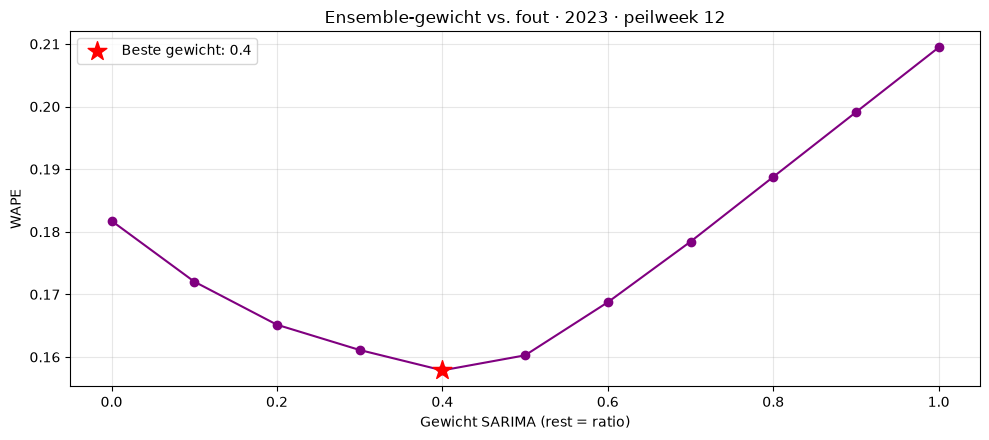

,w_sarima,WAPE
0,0.0,0.182
1,0.1,0.172
2,0.2,0.165
3,0.3,0.161
4,0.4,0.158
5,0.5,0.160
6,0.6,0.169
7,0.7,0.178
8,0.8,0.189
9,0.9,0.199


In [6]:
def wape(pred):
    return float((pred - df["Realisatie"]).abs().sum() / df["Realisatie"].sum())


sweep = pd.DataFrame([
    {"w_sarima": w, "WAPE": wape(w * df["SARIMA_cumulative"] + (1 - w) * df["Prognose_ratio"])}
    for w in np.linspace(0, 1, 11)
])
opt = sweep.loc[sweep["WAPE"].idxmin()]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(sweep["w_sarima"], sweep["WAPE"], "o-", color="purple")
ax.scatter([opt["w_sarima"]], [opt["WAPE"]], s=200, marker="*", color="red", zorder=5,
           label=f"Beste gewicht: {opt['w_sarima']:.1f}")
ax.set_xlabel("Gewicht SARIMA (rest = ratio)")
ax.set_ylabel("WAPE")
ax.set_title(f"Ensemble-gewicht vs. fout · {PREDICT_YEAR} · peilweek {PREDICT_WEEK}")
ax.legend()
plt.tight_layout()
plt.show()
sweep.round(3)


## 4. Onenigheid tussen modellen als waarschuwing

Een ensemble wint zelden van het beste losse model voor één opleiding: het is een
gemiddelde. De waarde zit in **stabiliteit**. Lopen de modellen ver uiteen, dan is dat
een signaal dat er één naast zit.


In [7]:
df["spreiding_%"] = ((df["SARIMA_cumulative"] - df["Prognose_ratio"]).abs() / df["Realisatie"] * 100).round(1)
df["beste"] = np.where(
    (df["SARIMA_cumulative"] - df["Realisatie"]).abs() < (df["Prognose_ratio"] - df["Realisatie"]).abs(),
    "SARIMA", "ratio",
)
df.assign(opleiding=[label(c, NAMEN, 30) for c in df["Croho groepeernaam"]])[
    ["opleiding", "Herkomst", "Realisatie", "SARIMA_cumulative", "Prognose_ratio", "spreiding_%", "beste"]
].sort_values("spreiding_%", ascending=False).head(8)


,opleiding,Herkomst,Realisatie,SARIMA_cumulative,Prognose_ratio,spreiding_%,beste
6,39111 B Vormgeving,Niet-EER,16,49.0,33.571429,96.4,ratio
0,30029 B International Business,EER,95,146.0,235.046400,93.7,SARIMA
2,30029 B International Business,Niet-EER,100,111.0,203.771661,92.8,SARIMA
25,56604 B Psychologie,Niet-EER,73,131.0,92.045455,53.4,ratio
4,39111 B Vormgeving,EER,77,85.0,121.475590,47.4,SARIMA
32,56990 B Biomedische Wetenschap,Niet-EER,16,25.0,17.518293,46.8,ratio
11,50439 B Mechanical Engineering,EER,116,199.0,149.576370,42.6,ratio
16,50950 B Economie en Bedrijfsec,EER,440,337.0,521.739771,42.0,ratio


## 5. Gewichten in productie

In productie bepaalt `scripts/calculate_ensemble_weights.py` de gewichten per
**opleiding × examentype × herkomst**, niet één globaal getal.

> ⚠️ **Gewichten verouderen.** Een model dat eerder goed presteerde kan na een
> beleidswijziging of uitzonderlijk jaar achterlopen. Herbereken ze elk studiejaar.

Het [CWF-model](02_cwf_model.ipynb) heeft geen gewichten nodig: het weegt per
combinatie zelf af tussen ratiosignaal en prior, en geeft er een interval bij.
